# 03. ECI 회귀분석 — AI 성능이 오를 때 청년 고용은 얼마나 변하나

- 입력: `data/processed/panel_analysis.csv` (직업 중분류 × 반기, 주 분석 표본 50개 직업)
- 출력: `reports/eci_regression_results.csv`, `reports/figures/fig10_노출도_계수_추이.png`
- 가설과 판정 기준은 `docs/ai_exposure_design_eda.md` 8-1절, 결과 변수는 8-9절.

**질문**: ECI가 10점 오를 때, AI 노출도가 1표준편차 높은 직업에서 "청년 ÷ 30~59세" 취업자 비율이 몇 % 더 변하는가?

직업 수준에서는 고용률을 정의할 수 없어(직업별 인구가 없음) ln(청년 취업자 ÷ 30~59세 취업자)를 쓴다. 계수 × 100은 대략 % 변화다.

In [1]:
import sys
import warnings

sys.path.append("..")  # 노트북 폴더 기준으로 src를 찾는다 (README 6절)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from matplotlib import font_manager

from src import config

warnings.filterwarnings("ignore", category=FutureWarning)
INK2, MUTED, GRID, AXIS, SURFACE, BLUE = "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb", "#2a78d6"
_fonts = {f.name for f in font_manager.fontManager.ttflist}
FONT = next(f for f in ["AppleGothic", "Malgun Gothic", "NanumGothic", "DejaVu Sans"] if f in _fonts)
sns.set_theme(style="whitegrid", font=FONT, rc={
    "axes.unicode_minus": False, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.edgecolor": AXIS, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 8, "ytick.labelsize": 8, "axes.labelsize": 9,
    "axes.titleweight": "bold", "axes.titlesize": 10, "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
})

df = pd.read_csv(config.DATA_PROCESSED / "panel_analysis.csv", dtype={"code": str, "period": str})
# ECI 상승폭: 2023 상반기(GPT-4 수준) 대비, 10점 단위. 2022년 이전은 0
df["eci_gain"] = ((df.eci - df.loc[df.period == "202301", "eci"].iloc[0]) / 10).fillna(0)
df["t"] = df.time - df.loc[df.period == "202202", "time"].iloc[0]   # 2022 하반기 = 0 (연 단위)
PERIODS = sorted(df.period.unique())
df["pi"] = df.period.map({p: i for i, p in enumerate(PERIODS)})
df["x_eci"] = df.exp_z * df.eci_gain      # 노출도 × ECI 상승폭
df["x_k"] = df.exp_z * df.k_post          # 노출도 × 2023년 이후 경과 반기 수
main = df[df.in_main].copy()
print(main.drop_duplicates("period").set_index("period").loc["202202":, ["eci", "eci_gain", "k_post"]].round(2).to_string())

results = []


def fit(data, terms, y="lr_y", trend=False, code_fe=True, weighted=True):
    """가중 회귀(가중치 = 2022년 청년 취업자), 표준오차는 직업 단위 군집.

    직업 고유값과 시점 공통값은 더미로 넣는다. trend=True면 직업별 직선 추세를 더한다.
    추세 더미는 하나를 빼야 시점 더미와 겹치지 않는다(모든 직업의 추세를 더하면 시간 그 자체가 되기 때문).
    """
    data = data[data.w > 0] if weighted else data
    parts = [data[terms], pd.get_dummies(data.period, prefix="p", drop_first=True)]
    if code_fe:
        parts.append(pd.get_dummies(data.code, prefix="c", drop_first=True))
    if trend:
        parts.append(pd.get_dummies(data.code, prefix="tr", drop_first=True).mul(data.t, axis=0))
    X = sm.add_constant(pd.concat(parts, axis=1).astype(float))
    assert np.linalg.matrix_rank(X.values) == X.shape[1], "설명변수끼리 겹침(완전 공선성)"
    w = data.w if weighted else np.ones(len(data))
    return sm.WLS(data[y], X, weights=w).fit(cov_type="cluster", cov_kwds={"groups": data.code.astype("category").cat.codes})


def add(block, name, res, term):
    lo, hi = res.conf_int().loc[term]
    results.append({"구분": block, "모형": name, "계수×100": 100 * res.params[term], "95% 하한": 100 * lo, "95% 상한": 100 * hi,
                    "p값": res.pvalues[term], "관측 수": int(res.nobs)})


def show(block):
    print(pd.DataFrame([r for r in results if r["구분"] == block]).drop(columns="구분").round(3).to_string(index=False))

           eci  eci_gain  k_post
period                          
202202     NaN      0.00       0
202301  121.87      0.00       1
202302  121.87      0.00       2
202401  125.87      0.40       3
202402  135.38      1.35       4
202501  143.91      2.20       5
202502  151.17      2.93       6
202601  160.17      3.83       7


## 1. 주 모형

- **A**: 직업 고유값과 시점 공통값만 넣은 단순 모형.
- **B (주)**: A에 직업별 원래 추세를 더한 모형. EDA에서 본 "2013년부터 있던 흐름"을 걷어낸다.
- **C**: B에서 ECI 대신 "2023년 이후 경과 반기 수"를 넣은 모형(가설 H1의 원래 식).
- **D**: ECI와 경과 반기 수를 함께 넣은 모형. 둘이 거의 같이 움직여서 구분되지 않을 것으로 예상한다.

In [2]:
add("주 모형", "A 고정효과만: 노출도×ECI", fit(main, ["x_eci"]), "x_eci")
add("주 모형", "B 직업별 추세 포함: 노출도×ECI (주)", fit(main, ["x_eci"], trend=True), "x_eci")
add("주 모형", "C 직업별 추세 포함: 노출도×경과 반기", fit(main, ["x_k"], trend=True), "x_k")
both = fit(main, ["x_eci", "x_k"], trend=True)
add("주 모형", "D 둘 다 넣음: 노출도×ECI", both, "x_eci")
add("주 모형", "D 둘 다 넣음: 노출도×경과 반기", both, "x_k")
show("주 모형")

                      모형  계수×100  95% 하한  95% 상한    p값  관측 수
        A 고정효과만: 노출도×ECI  -4.160  -7.093  -1.228 0.005  1350
B 직업별 추세 포함: 노출도×ECI (주)  -0.140  -0.976   0.695 0.742  1350
  C 직업별 추세 포함: 노출도×경과 반기   0.035  -0.452   0.522 0.887  1350
       D 둘 다 넣음: 노출도×ECI  -1.457  -3.837   0.922 0.230  1350
     D 둘 다 넣음: 노출도×경과 반기   0.781  -0.598   2.160 0.267  1350


## 2. 시점별 계수 (event study)

노출도의 계수를 시점마다 따로 추정한다(기준 2022 하반기 = 0). 처치 전 계수가 0 근처에서 평평해야 단순 모형 A를 믿을 수 있다.

period  coef    lo   hi
201301  18.8   5.8 31.7
201302  16.4   3.9 28.8
201401  15.8   4.2 27.3
201402  11.9   3.3 20.6
201501  13.2   3.4 23.0
201502   9.8  -0.0 19.6
201601  11.1   3.0 19.1
201602  10.5   2.6 18.5
201701  10.1   2.5 17.7
201702   8.1   0.3 15.8
201801   6.6  -0.7 13.8
201802   5.0  -1.1 11.2
201901   4.0  -1.5  9.6
201902   3.6  -0.8  7.9
202001   3.3  -1.6  8.3
202002   3.1  -0.9  7.0
202101   2.8  -0.4  6.0
202102   3.7   0.6  6.7
202201   3.2   0.6  5.9
202202   0.0   0.0  0.0
202301  -0.6  -3.1  1.9
202302  -0.5  -3.9  2.9
202401  -2.3  -5.7  1.2
202402  -1.1  -4.9  2.8
202501  -3.3  -6.5 -0.2
202502  -4.2  -8.5  0.1
202601  -7.7 -11.6 -3.9

계수의 연간 기울기: 2013~2019 -2.17, 2019 하~2022 상 -0.06, 2022 하~2026 상 -1.89


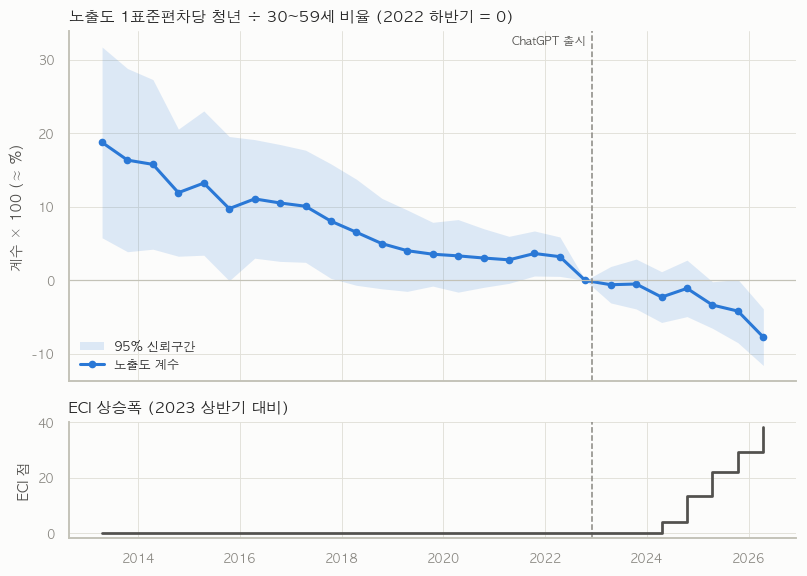

In [3]:
ev = main.copy()
terms = []
for p in PERIODS:
    if p != "202202":
        ev[f"e_{p}"] = ev.exp_z * (ev.period == p)
        terms.append(f"e_{p}")
es = fit(ev, terms)
path = pd.DataFrame({"period": [t[2:] for t in terms], "coef": 100 * es.params[terms].values,
                     "lo": 100 * es.conf_int().loc[terms, 0].values, "hi": 100 * es.conf_int().loc[terms, 1].values})
path = pd.concat([path, pd.DataFrame([{"period": "202202", "coef": 0, "lo": 0, "hi": 0}])]).sort_values("period")
path = path.merge(main.drop_duplicates("period")[["period", "time", "eci_gain"]], on="period")
print(path[["period", "coef", "lo", "hi"]].round(1).to_string(index=False))

slope = lambda a, b: np.polyfit(path[(path.period >= a) & (path.period <= b)].time, path[(path.period >= a) & (path.period <= b)].coef, 1)[0]
print(f"\n계수의 연간 기울기: 2013~2019 {slope('201301', '201902'):.2f}, 2019 하~2022 상 {slope('201902', '202201'):.2f}, 2022 하~2026 상 {slope('202202', '202601'):.2f}")

fig, (ax, ax2) = plt.subplots(2, 1, figsize=(7.5, 5.4), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ax.fill_between(path.time, path.lo, path.hi, color=BLUE, alpha=0.15, linewidth=0, label="95% 신뢰구간")
ax.plot(path.time, path.coef, color=BLUE, lw=2, marker="o", ms=4, label="노출도 계수")
ax.axhline(0, color=AXIS, lw=0.8)
CHATGPT = 2022 + 11 / 12
for a in (ax, ax2):
    a.axvline(CHATGPT, color=MUTED, lw=1, ls="--")
ax.annotate("ChatGPT 출시", (CHATGPT, 1), xycoords=("data", "axes fraction"), xytext=(-4, -3), textcoords="offset points", ha="right", va="top", fontsize=7.5, color=INK2)
ax.set(title="노출도 1표준편차당 청년 ÷ 30~59세 비율 (2022 하반기 = 0)", ylabel="계수 × 100 (≈ %)")
ax.legend(frameon=False, fontsize=8, loc="lower left")
ax2.step(path.time, path.eci_gain * 10, where="post", color=INK2, lw=1.8)
ax2.set(title="ECI 상승폭 (2023 상반기 대비)", ylabel="ECI 점", xlabel="")
fig.tight_layout()
fig.savefig(config.FIGURES / "fig10_노출도_계수_추이.png")

## 3. 가짜 시점 검정 (H2)

AI가 없던 2017년 상반기와 2019년 상반기를 "시작"으로 두고, 2022년까지의 자료만으로 같은 식을 돌린다. 여기서도 효과가 나오면 그 모형은 AI 효과를 가려내지 못한다.

In [4]:
add("가짜 시점", "실제(2023 상~), 고정효과만: 노출도×경과 반기", fit(main, ["x_k"]), "x_k")
add("가짜 시점", "실제(2023 상~), 직업별 추세: 노출도×경과 반기", fit(main, ["x_k"], trend=True), "x_k")
pre = main[~main.post].copy()
for fake in ("201701", "201901"):
    pre["x_fake"] = pre.exp_z * (pre.pi - PERIODS.index(fake) + 1).clip(lower=0)
    add("가짜 시점", f"가짜({fake[:4]} 상~), 고정효과만", fit(pre, ["x_fake"]), "x_fake")
    add("가짜 시점", f"가짜({fake[:4]} 상~), 직업별 추세", fit(pre, ["x_fake"], trend=True), "x_fake")
show("가짜 시점")

                            모형  계수×100  95% 하한  95% 상한    p값  관측 수
 실제(2023 상~), 고정효과만: 노출도×경과 반기  -2.296  -4.023  -0.570 0.009  1350
실제(2023 상~), 직업별 추세: 노출도×경과 반기   0.035  -0.452   0.522 0.887  1350
            가짜(2017 상~), 고정효과만  -1.083  -1.919  -0.248 0.011  1000
           가짜(2017 상~), 직업별 추세   0.562  -0.153   1.278 0.124  1000
            가짜(2019 상~), 고정효과만  -1.419  -2.626  -0.212 0.021  1000
           가짜(2019 상~), 직업별 추세   0.662  -0.073   1.397 0.077  1000


## 4. 처치 전 추세를 어떻게 잡느냐에 따른 차이

모형 B는 직업별 추세를 전체 기간으로 추정해서, 2023년 이후의 변화 일부를 추세로 흡수할 수 있다. 그래서 추세를 처치 전 자료만으로 추정해 2023년 이후로 연장하고, 실제 값이 그 연장선에서 벗어난 정도를 ECI로 설명해 본다. 추세 기간을 세 가지로 바꿔 본다.

In [5]:
for label, lo, hi in (("2013~2022", "201301", "202202"), ("2013~2019(코로나 이전)", "201301", "201902"), ("2019 하~2022(최근)", "201902", "202202")):
    span = main[(main.period >= lo) & (main.period <= hi)]
    tr = span.groupby("code").apply(lambda d: pd.Series(np.polyfit(d.t, d.lr_y, 1), index=["slope", "icpt"]), include_groups=False)
    d = main.join(tr, on="code")
    d["dev"] = d.lr_y - (d.icpt + d.slope * d.t)
    add("추세 기간", f"추세 {label}: 이탈 ~ 노출도×ECI", fit(d[d.post], ["exp_z", "x_eci"], y="dev", code_fe=False), "x_eci")
show("추세 기간")

                                모형  계수×100  95% 하한  95% 상한    p값  관측 수
        추세 2013~2022: 이탈 ~ 노출도×ECI  -0.353  -1.224   0.518 0.427   350
추세 2013~2019(코로나 이전): 이탈 ~ 노출도×ECI  -0.049  -0.971   0.874 0.918   350
  추세 2019 하~2022(최근): 이탈 ~ 노출도×ECI  -1.049  -2.122   0.024 0.055   350


## 5. 표본과 변수를 바꿔 보기

모형 A와 B를 가중치 없이, 표본을 바꿔서, 2023년 노출도 점수로 다시 추정한다.

In [6]:
exp23_z = (df.exp23 - df.drop_duplicates("code").exp23.mean()) / df.drop_duplicates("code").exp23.std()
variants = {
    "가중치 없음": (main, "lr_y", "x_eci", False),
    "47개 직업(오차 표시 많은 3개 추가 제외)": (main[main.in_robust47], "lr_y", "x_eci", True),
    "코로나 시기(2020~2021) 제외": (main[~main.covid], "lr_y", "x_eci", True),
    "2023년 노출도 점수": (main.assign(x_eci23=exp23_z[main.index] * main.eci_gain), "lr_y", "x_eci23", True),
    "결과 = 청년 비중(%p), 청년이 있는 55개 직업": (df.assign(y_share=df.y_share / 100), "y_share", "x_eci", True),
}
for name, (data, y, x, weighted) in variants.items():
    add("바꿔 보기", f"A 고정효과만 | {name}", fit(data, [x], y=y, weighted=weighted), x)
    add("바꿔 보기", f"B 직업별 추세 | {name}", fit(data, [x], y=y, trend=True, weighted=weighted), x)
show("바꿔 보기")

                                      모형  계수×100  95% 하한  95% 상한    p값  관측 수
                        A 고정효과만 | 가중치 없음  -4.480  -6.427  -2.534 0.000  1350
                       B 직업별 추세 | 가중치 없음  -0.180  -1.514   1.154 0.791  1350
     A 고정효과만 | 47개 직업(오차 표시 많은 3개 추가 제외)  -4.149  -7.092  -1.206 0.006  1269
    B 직업별 추세 | 47개 직업(오차 표시 많은 3개 추가 제외)  -0.148  -0.986   0.691 0.730  1269
          A 고정효과만 | 코로나 시기(2020~2021) 제외  -4.433  -7.549  -1.316 0.005  1150
         B 직업별 추세 | 코로나 시기(2020~2021) 제외  -0.118  -0.940   0.703 0.778  1150
                  A 고정효과만 | 2023년 노출도 점수  -4.311  -7.199  -1.422 0.003  1350
                 B 직업별 추세 | 2023년 노출도 점수   0.015  -0.762   0.792 0.970  1350
 A 고정효과만 | 결과 = 청년 비중(%p), 청년이 있는 55개 직업  -0.461  -0.870  -0.052 0.027  1458
B 직업별 추세 | 결과 = 청년 비중(%p), 청년이 있는 55개 직업  -0.035  -0.179   0.109 0.635  1458


In [7]:
out = pd.DataFrame(results)
out.to_csv(config.FIGURES.parent / "eci_regression_results.csv", index=False, encoding="utf-8-sig")
print("저장:", len(out), "행")

저장: 24 행


## 요약 (2026-11-23 실행 기준)

단위는 "ECI 10점 상승 × 노출도 1표준편차"당 청년 ÷ 30~59세 비율의 변화(%)다.

1. **단순 모형 A는 -4.2%** (95% 신뢰구간 -7.1 ~ -1.2). 표본과 변수를 바꿔도 -4.1 ~ -4.5로 유지된다.
2. **그러나 A는 AI 효과를 가려내지 못한다.** AI가 없던 가짜 시점(2017, 2019)에서도 같은 방향의 유의한 값이 나온다(반기당 -1.1, -1.4. 실제는 -2.3). 시점별 계수도 2013년부터 계속 내려왔다.
3. **직업별 원래 추세를 넣은 주 모형 B는 -0.1%** (-1.0 ~ +0.7)로 0과 구분되지 않는다. 표본과 변수를 바꿔도 -0.2 ~ 0.0이다.
4. **추세를 어느 기간으로 잡느냐에 따라 달라진다.** 시점별 계수의 연간 기울기는 2013~2019년 -2.2, 2019 하~2022 상 -0.1, 2022 하~2026 상 -1.9다. 2019~2022년의 정체를 기준으로 삼으면 2023년 이후 다시 내려간 것으로 보이고(-1.0%, 신뢰구간 -2.1 ~ 0.0), 2013년부터의 추세를 기준으로 삼으면 원래 속도로 돌아온 것으로 보인다(-0.0 ~ -0.4%).
5. **ECI와 경과 시간은 구분되지 않는다.** 둘을 함께 넣은 모형 D에서는 둘 다 0과 구분되지 않는다.

**결론**: 이 자료로는 "ECI가 오를 때 노출도 높은 직업의 청년 고용이 더 줄었다"고 말할 수 없다. 말할 수 있는 범위는 "효과가 있더라도 ECI 10점당 0 ~ -1% 정도이고, 0일 가능성을 배제하지 못한다"이다.